# Results

Reads `models/training_runs/results.csv` and the saved models, scores the test set, and makes every table and figure for the report.

- Report figures (all models together) are saved to `reports/figures/`.
- One figure per model is saved to `reports/figures/per_model/`.

Don't re-run `Feature_Engineer.ipynb` before this notebook: the saved models must be scored on the same data they were trained on.

In [1]:
import sys
sys.path.append("../src")

import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from training.data import load_processed_data
from training.dl_models import build_dl_model
from training.metrics import compute_metrics, to_wh
from training.torch_loop import predict
from training.windows import make_window_datasets

RUNS = Path("../models/training_runs")
FIGURES = Path("../reports/figures")
PER_MODEL = FIGURES / "per_model"
PER_MODEL.mkdir(parents=True, exist_ok=True)

NAMES = {
    "linear": "Linear Regression", "ridge": "Ridge", "decision_tree": "Decision Tree",
    "random_forest": "Random Forest", "gradient_boosting": "Gradient Boosting",
    "xgboost": "XGBoost", "catboost": "CatBoost",
    "gru": "GRU", "lstm": "LSTM", "cnn_lstm": "CNN-LSTM",
}
DL_MODELS = ["gru", "lstm", "cnn_lstm"]

pd.set_option("display.max_colwidth", None)

results = pd.read_csv(RUNS / "results.csv")
results = results.drop_duplicates("experiment", keep="last")   # if a run was repeated, keep the newest
results["name"] = results["model"].map(NAMES)
results.shape

(36, 43)

## 1. Validation results (used to choose the settings)

Best run of each model on the validation set, with its training time (report 6.3).

In [2]:
best = results.sort_values("val_rmse").drop_duplicates("model")
best[["name", "val_mae", "val_rmse", "val_mape", "val_r2", "train_seconds"]].round(2)

,name,val_mae,val_rmse,val_mape,val_r2,train_seconds
15,CatBoost,13.05,20.29,18.06,0.73,4.6
10,XGBoost,13.12,20.37,18.14,0.72,0.9
6,Random Forest,13.25,20.52,18.25,0.72,5.9
35,CNN-LSTM,13.20,20.54,18.52,0.72,33.1
21,GRU,13.28,20.55,18.41,0.72,107.1
8,Gradient Boosting,13.41,20.56,18.57,0.72,38.8
29,LSTM,13.31,20.60,18.57,0.72,19.5
4,Decision Tree,13.40,20.97,18.53,0.71,0.3
3,Ridge,13.59,21.06,18.82,0.71,0.0
0,Linear Regression,13.60,21.07,18.81,0.70,0.0


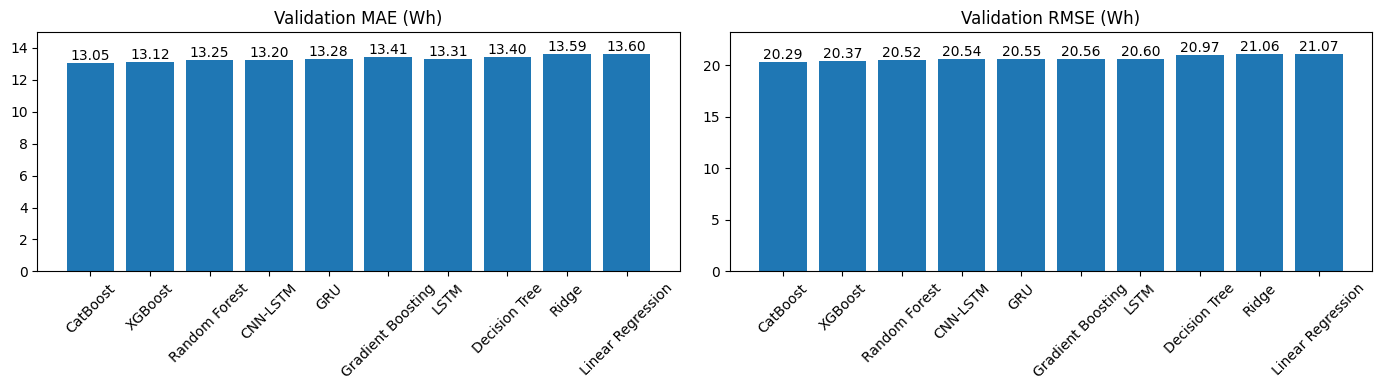

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric, title in zip(axes, ["val_mae", "val_rmse"], ["Validation MAE (Wh)", "Validation RMSE (Wh)"]):
    bars = ax.bar(best["name"], best[metric])
    ax.bar_label(bars, fmt="%.2f")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    ax.margins(y=0.1)
plt.tight_layout()
plt.savefig(FIGURES / "model_comparison_val.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Grid search (report 7.1 - 7.3)

Values tried for each setting, and the number of runs per model.

In [4]:
grid = results[results["notes"] == "grid search"]

rows = []
for model, runs in grid.groupby("model"):
    settings = pd.DataFrame(list(runs["model_params"].apply(json.loads)))
    if model in DL_MODELS:
        settings["learning_rate"] = runs["learning_rate"].values
    for setting in settings.columns.drop("n_jobs", errors="ignore"):
        rows.append({"name": NAMES[model], "setting": setting, "values tried": sorted(settings[setting].dropna().unique().tolist())})

print(grid.groupby("name").size().rename("runs").to_string())
pd.DataFrame(rows)

name
CNN-LSTM              4
CatBoost              2
Decision Tree         2
GRU                  12
Gradient Boosting     2
LSTM                  4
Linear Regression     1
Random Forest         2
Ridge                 3
XGBoost               4


,name,setting,values tried
0,CatBoost,depth,"[4, 6]"
1,CatBoost,iterations,[500]
2,CatBoost,learning_rate,[0.05]
3,CNN-LSTM,dropout,"[0.0, 0.2]"
4,CNN-LSTM,hidden_size,"[32, 64]"
5,CNN-LSTM,learning_rate,[0.001]
6,Decision Tree,max_depth,"[6, 10]"
7,Gradient Boosting,learning_rate,"[0.05, 0.1]"
8,Gradient Boosting,max_depth,[3]
9,Gradient Boosting,n_estimators,[300]


Best settings for each model.

In [5]:
best[["name", "model_params", "learning_rate", "val_rmse"]]

,name,model_params,learning_rate,val_rmse
15,CatBoost,"{""depth"": 6, ""iterations"": 500, ""learning_rate"": 0.05}",NaN,20.2857
10,XGBoost,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_estimators"": 300}",NaN,20.3695
6,Random Forest,"{""max_depth"": 8, ""n_estimators"": 200, ""n_jobs"": -1}",NaN,20.5202
35,CNN-LSTM,"{""dropout"": 0.2, ""hidden_size"": 64}",0.0010,20.5433
21,GRU,"{""dropout"": 0.0, ""hidden_size"": 128}",0.0003,20.5495
8,Gradient Boosting,"{""learning_rate"": 0.05, ""max_depth"": 3, ""n_estimators"": 300}",NaN,20.5630
29,LSTM,"{""dropout"": 0.0, ""hidden_size"": 64}",0.0010,20.5958
4,Decision Tree,"{""max_depth"": 6}",NaN,20.9727
3,Ridge,"{""alpha"": 10.0}",NaN,21.0586
0,Linear Regression,{},NaN,21.0693


Dropout comparison: best validation RMSE for each dropout rate (report 7.2).

In [6]:
dl = grid[grid["model"].isin(DL_MODELS)].copy()
dl["dropout"] = dl["model_params"].apply(lambda text: json.loads(text).get("dropout"))
dl.pivot_table(index="name", columns="dropout", values="val_rmse", aggfunc="min").round(2)

dropout,0.0,0.2
name,,
CNN-LSTM,20.57,20.54
GRU,20.55,20.70
LSTM,20.60,20.79


Epoch where early stopping kept the best weights (report 7.3).

In [7]:
dl.groupby("name")["best_epoch"].agg(["min", "median", "max"])

,min,median,max
name,,,
CNN-LSTM,6.0,7.5,12.0
GRU,4.0,12.0,17.0
LSTM,6.0,7.5,9.0


## 3. Test results

Loads each saved model and predicts the test set. Nothing is trained again. The predictions are saved as `predictions_test.csv` in each run folder.

In [8]:
splits, target_scaler, _ = load_processed_data("data", include_test=True)
X_test, y_test = splits["test"]
actual = to_wh(y_test, target_scaler)


def test_saved_run(run):
    """Load a run's saved model, predict the test set, save predictions_test.csv and return the test metrics."""
    run_dir = RUNS / run["run_dir"]
    if run["model"] in DL_MODELS:
        config = json.loads((run_dir / "config.json").read_text())
        test_set, _ = make_window_datasets(splits, config["sequence_length"])["test"]
        model = build_dl_model(config["model_name"], X_test.shape[1], config["model_params"])
        model.load_state_dict(torch.load(run_dir / "model.pt", map_location="cpu"))
        predicted = predict(model, test_set, 256, torch.device("cpu"))
    else:
        model = joblib.load(run_dir / "model.joblib")
        predicted = model.predict(X_test)

    predicted = to_wh(predicted, target_scaler)
    pd.DataFrame({"actual": actual, "predicted": predicted}).to_csv(run_dir / "predictions_test.csv", index=False)
    return compute_metrics(actual, predicted)

Test scores for the best run of every model (report 6.3).

In [9]:
rows = []
for _, run in best.iterrows():
    metrics = test_saved_run(run)
    rows.append({"name": run["name"], **{f"test_{key}": value for key, value in metrics.items()}})

test_results = pd.DataFrame(rows).round(2)
test_results

,name,test_mae,test_rmse,test_mape,test_r2
0,CatBoost,15.11,21.63,20.19,0.69
1,XGBoost,13.17,20.52,16.44,0.72
2,Random Forest,15.58,22.60,18.61,0.66
3,CNN-LSTM,13.93,20.90,18.34,0.71
4,GRU,15.37,21.60,20.87,0.69
5,Gradient Boosting,17.62,23.80,23.60,0.63
6,LSTM,15.23,21.67,20.57,0.69
7,Decision Tree,13.48,21.17,16.54,0.71
8,Ridge,13.58,21.07,17.48,0.71
9,Linear Regression,13.63,21.10,17.62,0.71


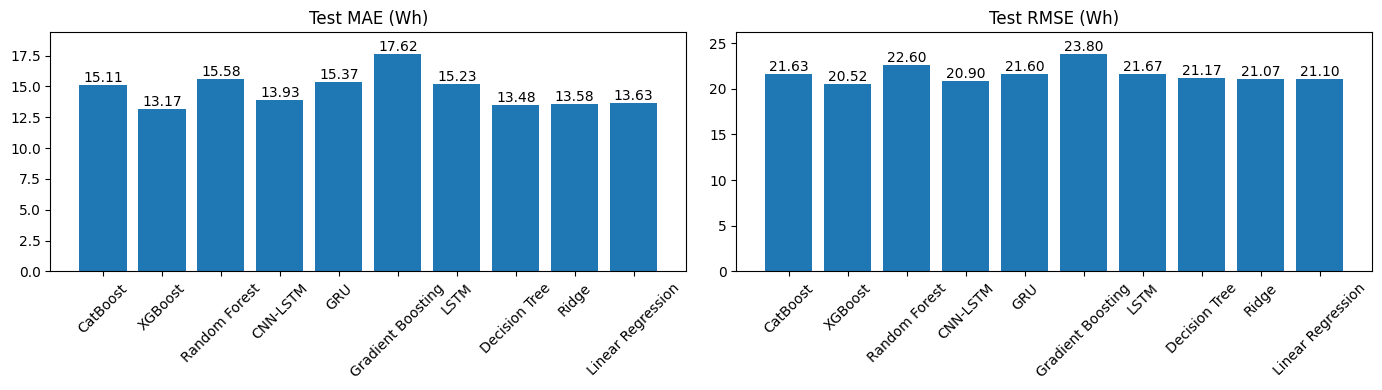

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metric, title in zip(axes, ["test_mae", "test_rmse"], ["Test MAE (Wh)", "Test RMSE (Wh)"]):
    bars = ax.bar(test_results["name"], test_results[metric])
    ax.bar_label(bars, fmt="%.2f")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    ax.margins(y=0.1)
plt.tight_layout()
plt.savefig(FIGURES / "model_comparison_test.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Before vs after tuning (report 7.4)

GRU with its default settings compared with the best GRU from the grid search, both scored on the test set.

In [11]:
gru = grid[grid["model"] == "gru"]
is_default = gru["model_params"].apply(json.loads).apply(lambda p: p == {"dropout": 0.2, "hidden_size": 64})
before_run = gru[is_default & (gru["learning_rate"] == 0.001)].iloc[0]   # the default GRU settings
after_run = best[best["model"] == "gru"].iloc[0]                         # the best GRU from the grid

before_after = pd.DataFrame([
    {"run": "Before (default)", "val_rmse": before_run["val_rmse"], **test_saved_run(before_run)},
    {"run": "After (tuned)", "val_rmse": after_run["val_rmse"], **test_saved_run(after_run)},
]).round(2)
before_after

,run,val_rmse,mae,rmse,mape,r2
0,Before (default),20.70,13.98,21.02,17.91,0.71
1,After (tuned),20.55,15.37,21.60,20.87,0.69


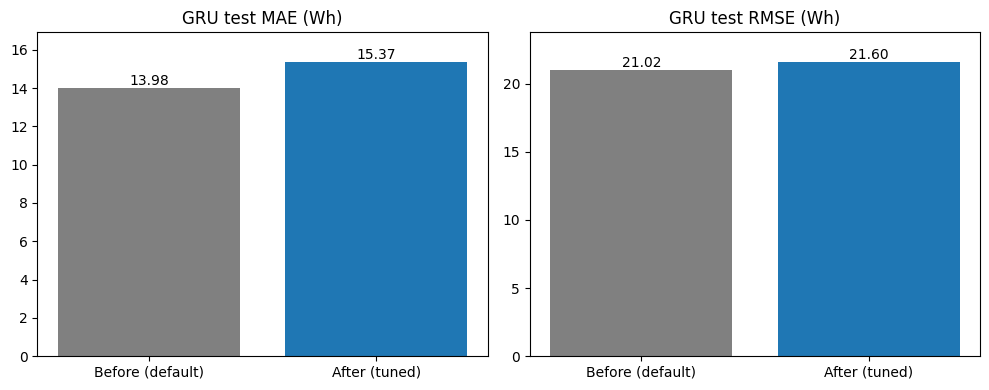

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, title in zip(axes, ["mae", "rmse"], ["GRU test MAE (Wh)", "GRU test RMSE (Wh)"]):
    bars = ax.bar(before_after["run"], before_after[metric], color=["grey", "tab:blue"])
    ax.bar_label(bars, fmt="%.2f")
    ax.set_title(title)
    ax.margins(y=0.1)
plt.tight_layout()
plt.savefig(FIGURES / "gru_before_after.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Plots of the test predictions, all models

The test predictions of every model, loaded once. `best` is sorted from best to worst validation RMSE.

In [13]:
predictions = {run["model"]: pd.read_csv(RUNS / run["run_dir"] / "predictions_test.csv") for _, run in best.iterrows()}
ml_runs = best[~best["model"].isin(DL_MODELS)]
dl_runs = best[best["model"].isin(DL_MODELS)]


def model_grid(n_models, n_cols, width=6, height=3):
    """Create one small plot per model and hide the unused ones."""
    n_rows = -(-n_models // n_cols)   # round up
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(width * n_cols, height * n_rows), squeeze=False)
    for ax in axes.flat[n_models:]:
        ax.axis("off")
    return fig, axes.flat

Actual vs predicted over time, first 3 days of the test set (report 6.4 / 8.2).

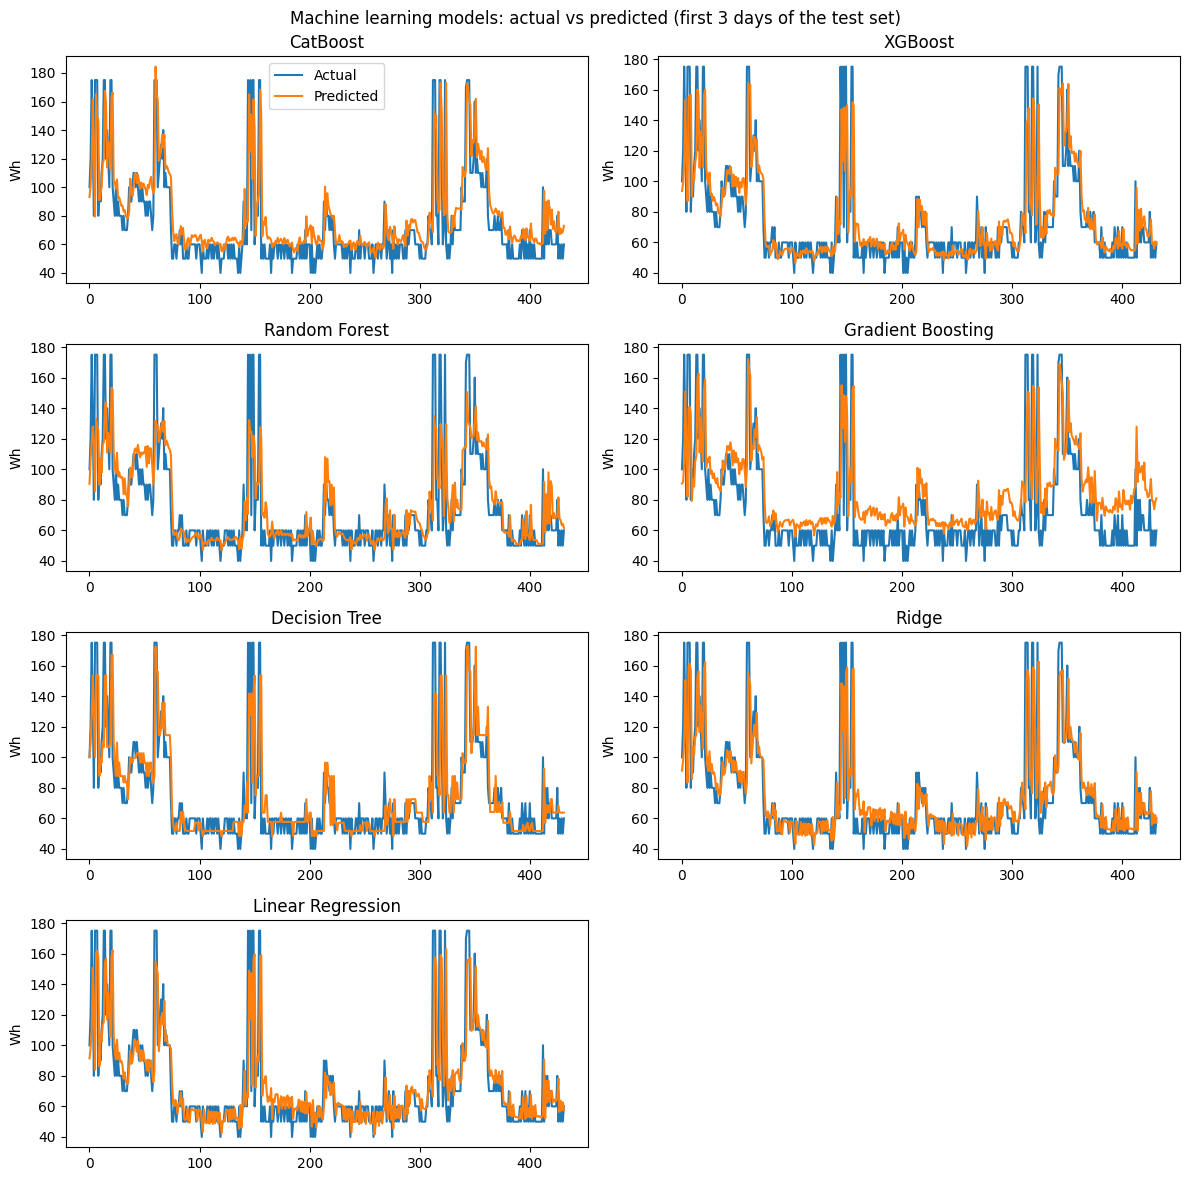

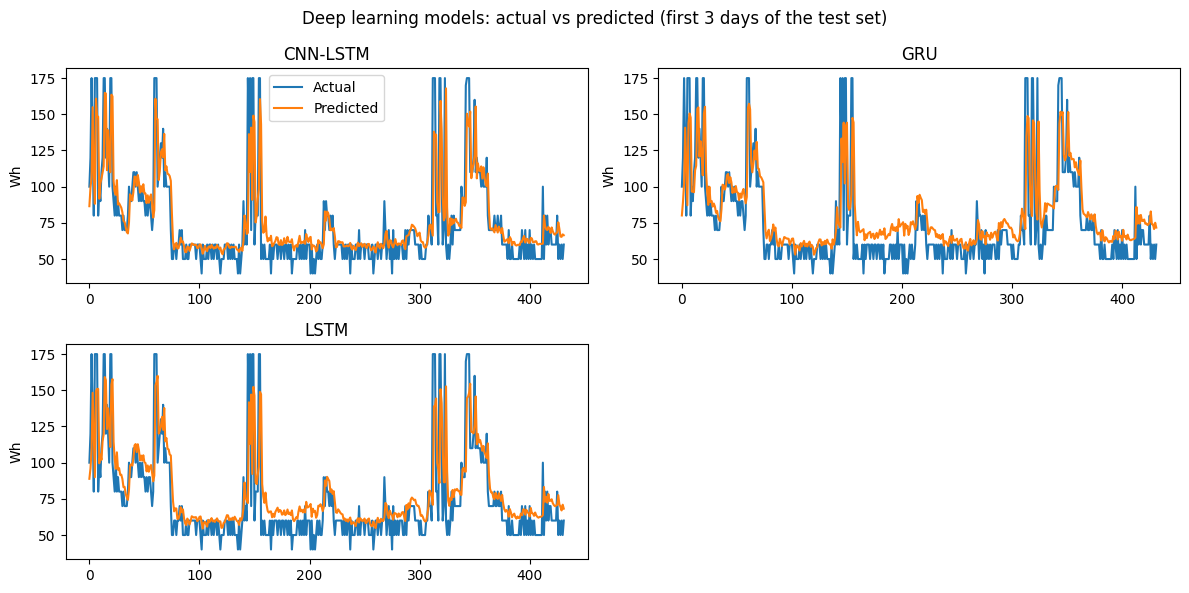

In [14]:
for runs, title, file_name in [(ml_runs, "Machine learning models", "actual_vs_predicted_ml.png"),
                               (dl_runs, "Deep learning models", "actual_vs_predicted_dl.png")]:
    fig, axes = model_grid(len(runs), n_cols=2)
    for ax, (_, run) in zip(axes, runs.iterrows()):
        days = predictions[run["model"]].iloc[:432]   # 3 days x 144 readings
        ax.plot(days["actual"], label="Actual")
        ax.plot(days["predicted"], label="Predicted")
        ax.set_title(run["name"])
        ax.set_ylabel("Wh")
    axes[0].legend()
    fig.suptitle(f"{title}: actual vs predicted (first 3 days of the test set)")
    plt.tight_layout()
    plt.savefig(FIGURES / file_name, dpi=200, bbox_inches="tight")
    plt.show()

Predicted vs actual for every test reading. Points on the red line are perfect predictions (report 6.4 / 8.2).

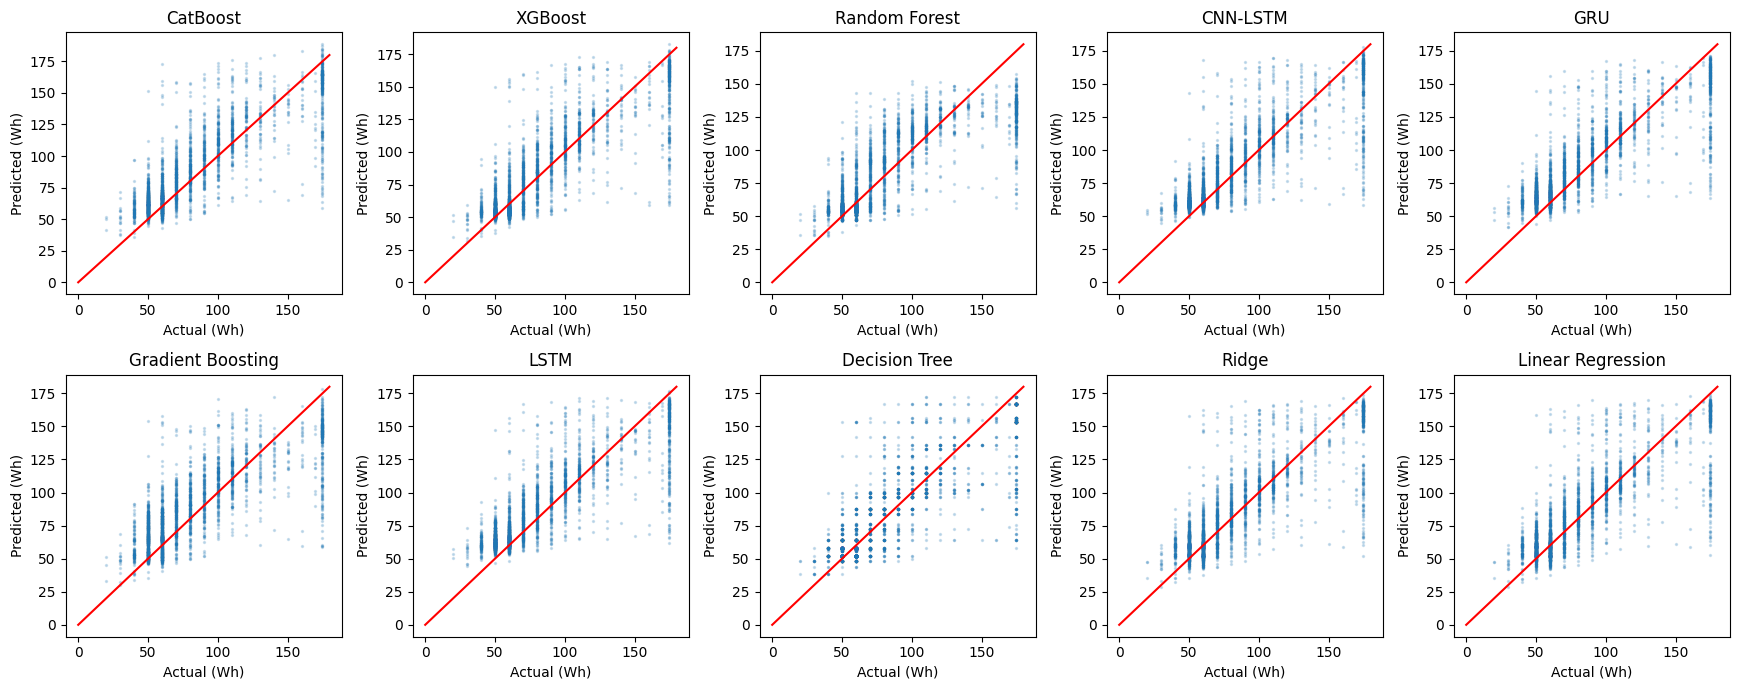

In [15]:
fig, axes = model_grid(len(best), n_cols=5, width=3.5, height=3.5)
for ax, (_, run) in zip(axes, best.iterrows()):
    pred = predictions[run["model"]]
    ax.scatter(pred["actual"], pred["predicted"], s=2, alpha=0.2)
    ax.plot([0, 180], [0, 180], color="red")
    ax.set_title(run["name"])
    ax.set_xlabel("Actual (Wh)")
    ax.set_ylabel("Predicted (Wh)")
plt.tight_layout()
plt.savefig(FIGURES / "predicted_vs_actual_scatter.png", dpi=200, bbox_inches="tight")
plt.show()

Residual distribution (actual minus predicted) for every model (report 6.4 / 8.3).

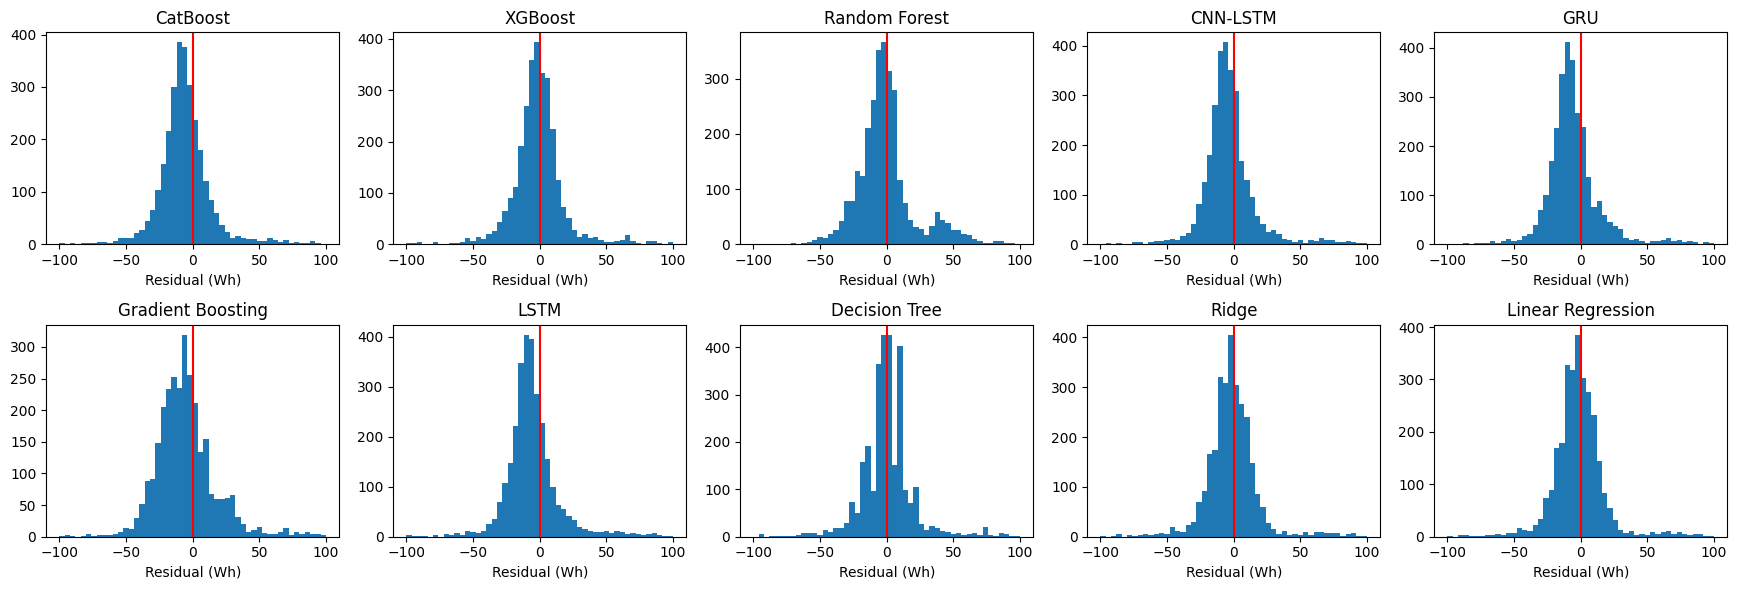

In [16]:
fig, axes = model_grid(len(best), n_cols=5, width=3.5, height=3)
for ax, (_, run) in zip(axes, best.iterrows()):
    pred = predictions[run["model"]]
    ax.hist(pred["actual"] - pred["predicted"], bins=50, range=(-100, 100))
    ax.axvline(0, color="red")
    ax.set_title(run["name"])
    ax.set_xlabel("Residual (Wh)")
plt.tight_layout()
plt.savefig(FIGURES / "residual_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

Residuals vs predicted value for every model (report 6.4 / 8.3).

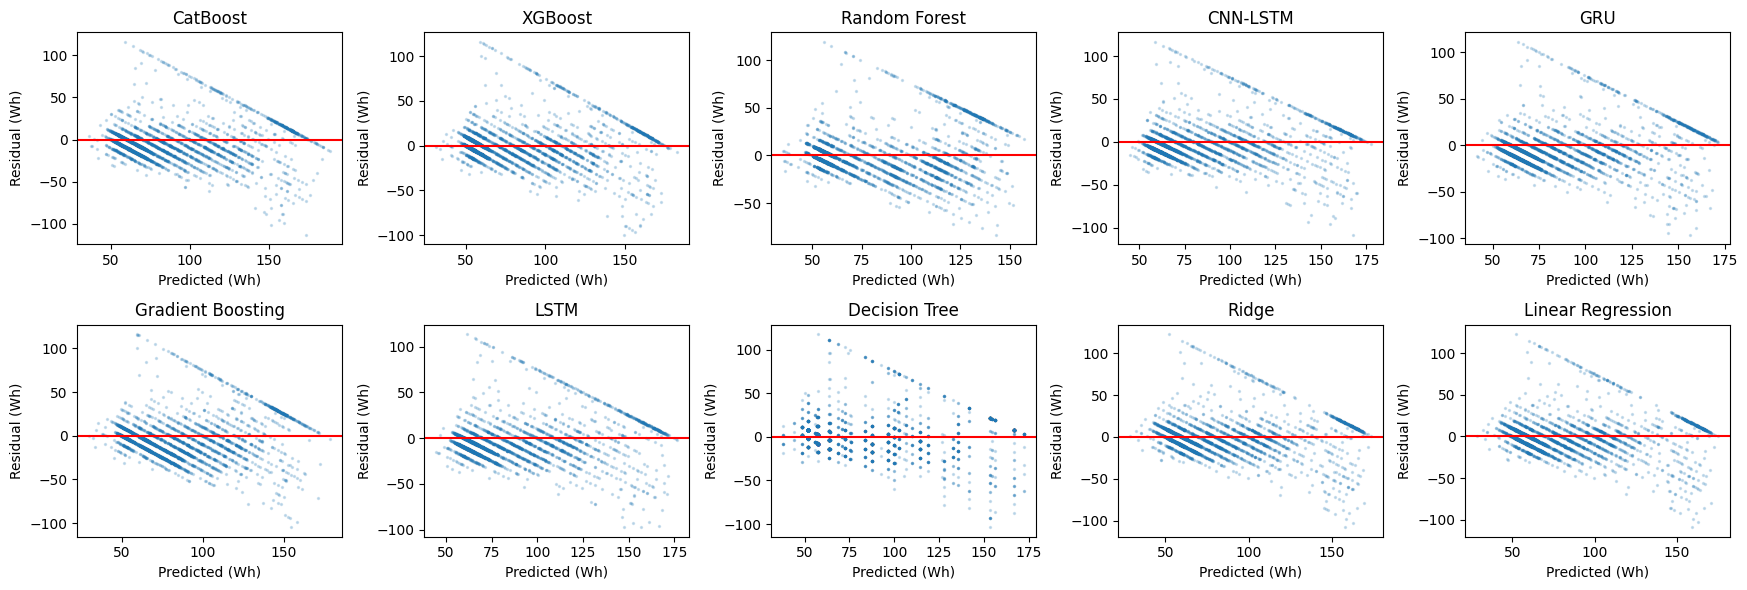

In [17]:
fig, axes = model_grid(len(best), n_cols=5, width=3.5, height=3)
for ax, (_, run) in zip(axes, best.iterrows()):
    pred = predictions[run["model"]]
    ax.scatter(pred["predicted"], pred["actual"] - pred["predicted"], s=2, alpha=0.2)
    ax.axhline(0, color="red")
    ax.set_title(run["name"])
    ax.set_xlabel("Predicted (Wh)")
    ax.set_ylabel("Residual (Wh)")
plt.tight_layout()
plt.savefig(FIGURES / "residuals_vs_predicted.png", dpi=200, bbox_inches="tight")
plt.show()

Learning curves of the deep learning models: training and validation loss per epoch (report 6.1).

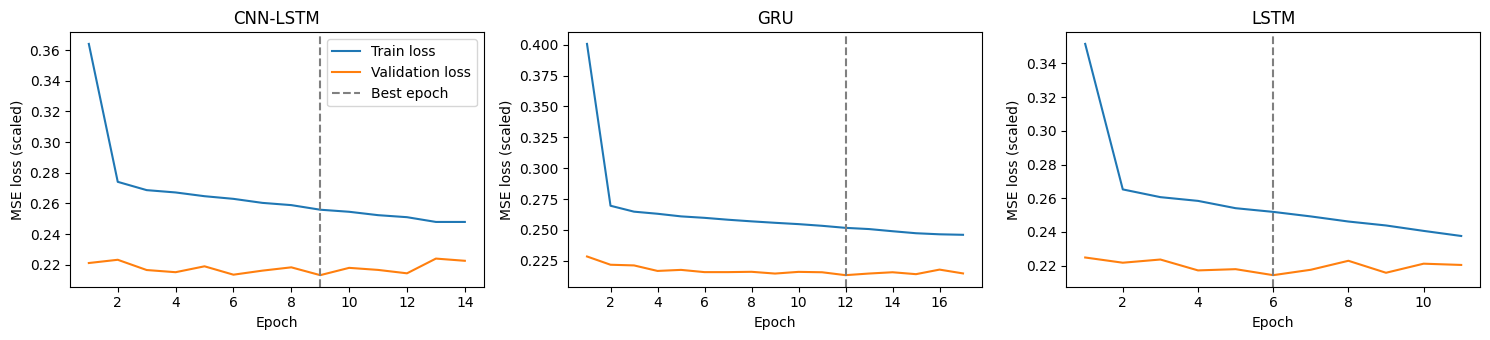

In [18]:
fig, axes = model_grid(len(dl_runs), n_cols=3, width=5, height=3.5)
for ax, (_, run) in zip(axes, dl_runs.iterrows()):
    history = pd.read_csv(RUNS / run["run_dir"] / "history.csv")
    ax.plot(history["epoch"], history["train_loss"], label="Train loss")
    ax.plot(history["epoch"], history["val_loss"], label="Validation loss")
    ax.axvline(run["best_epoch"], color="grey", linestyle="--", label="Best epoch")
    ax.set_title(run["name"])
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss (scaled)")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURES / "learning_curves.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Learning curves for the tree models

XGBoost, CatBoost and Gradient Boosting add trees one at a time, and Random Forest averages more and more trees. The saved models can predict with only the first few trees, so their train and validation error can be plotted without training again. Linear Regression, Ridge and Decision Tree are fitted in one step, so they have no curve (see the next figure instead).

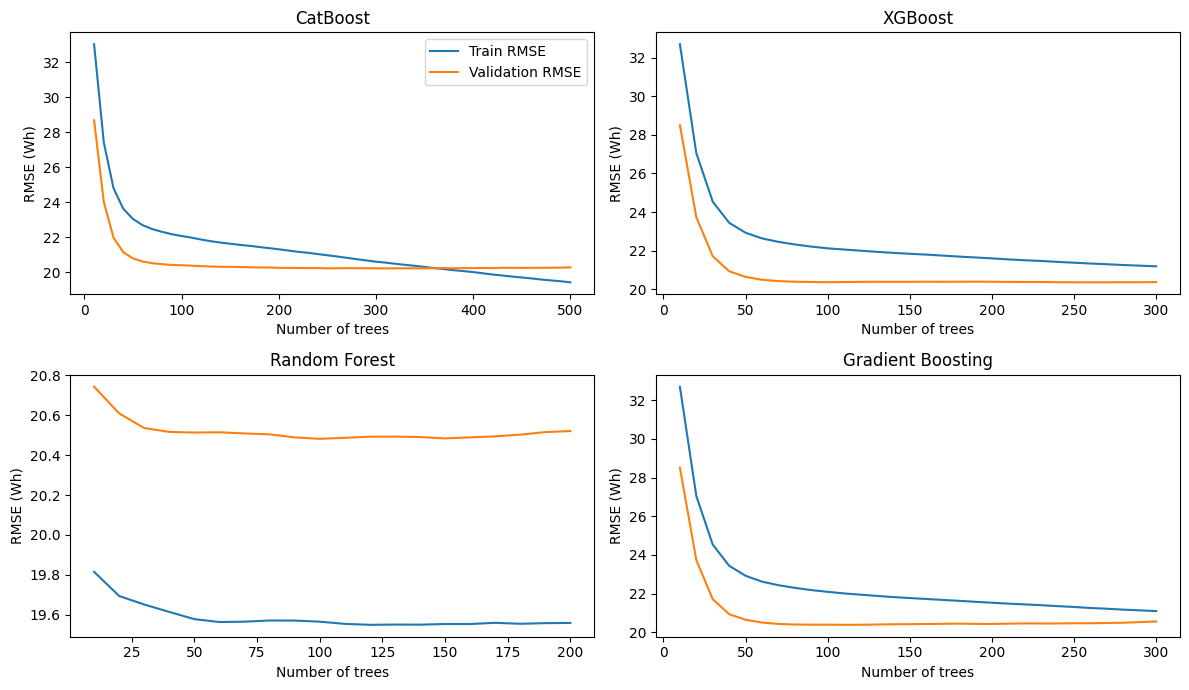

In [19]:
X_train, y_train = splits["train"]
X_val, y_val = splits["val"]
train_wh = to_wh(y_train, target_scaler)
val_wh = to_wh(y_val, target_scaler)


def predictions_by_trees(model_name, model, X):
    """Predictions using the first 10, 20, 30, ... trees of a saved model. Returns (number of trees, predictions) pairs."""
    if model_name == "xgboost":
        n_trees = model.get_booster().num_boosted_rounds()
        return [(k, model.predict(X, iteration_range=(0, k))) for k in range(10, n_trees + 1, 10)]
    if model_name == "catboost":
        return [(k, model.predict(X, ntree_end=k)) for k in range(10, model.tree_count_ + 1, 10)]
    if model_name == "gradient_boosting":
        return [(k + 1, pred) for k, pred in enumerate(model.staged_predict(X)) if (k + 1) % 10 == 0]
    if model_name == "random_forest":
        tree_predictions = np.array([tree.predict(X) for tree in model.estimators_])
        return [(k, tree_predictions[:k].mean(axis=0)) for k in range(10, len(tree_predictions) + 1, 10)]
    return []


def rmse_wh(actual_wh, predicted):
    return compute_metrics(actual_wh, to_wh(predicted, target_scaler))["rmse"]


tree_runs = best[best["model"].isin(["xgboost", "catboost", "gradient_boosting", "random_forest"])]

fig, axes = model_grid(len(tree_runs), n_cols=2, width=6, height=3.5)
for ax, (_, run) in zip(axes, tree_runs.iterrows()):
    model = joblib.load(RUNS / run["run_dir"] / "model.joblib")
    train_curve = [(k, rmse_wh(train_wh, pred)) for k, pred in predictions_by_trees(run["model"], model, X_train)]
    val_curve = [(k, rmse_wh(val_wh, pred)) for k, pred in predictions_by_trees(run["model"], model, X_val)]

    ax.plot(*zip(*train_curve), label="Train RMSE")
    ax.plot(*zip(*val_curve), label="Validation RMSE")
    ax.set_title(run["name"])
    ax.set_xlabel("Number of trees")
    ax.set_ylabel("RMSE (Wh)")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURES / "learning_curves_trees.png", dpi=200, bbox_inches="tight")
plt.show()

Train, validation and test RMSE for every model. A big gap between train and the other two means the model learned the training data too closely (overfitting).

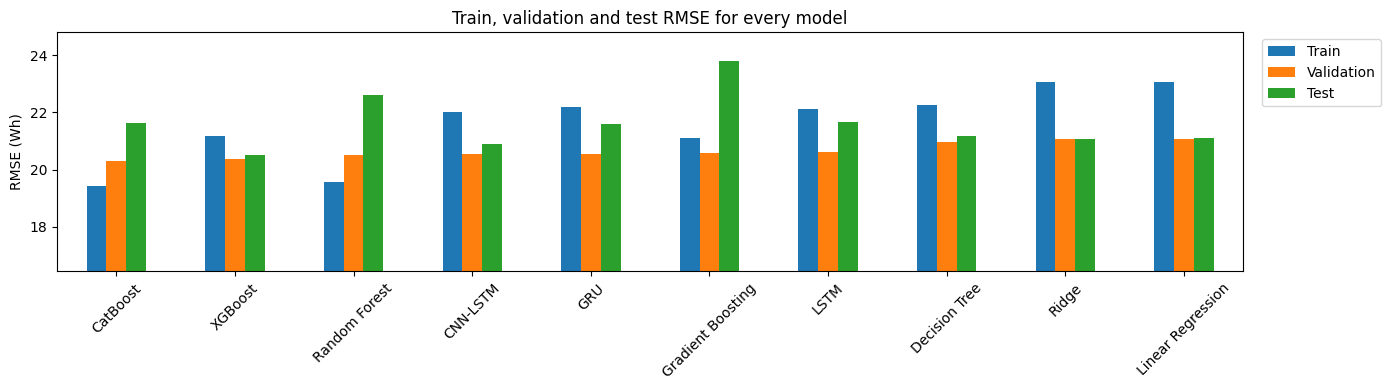

,Train,Validation,Test
name,,,
CatBoost,19.43,20.29,21.63
XGBoost,21.19,20.37,20.52
Random Forest,19.56,20.52,22.60
CNN-LSTM,22.00,20.54,20.90
GRU,22.20,20.55,21.60
Gradient Boosting,21.10,20.56,23.80
LSTM,22.10,20.60,21.67
Decision Tree,22.25,20.97,21.17
Ridge,23.06,21.06,21.07


In [20]:
errors = best[["name", "train_rmse", "val_rmse"]].merge(test_results[["name", "test_rmse"]], on="name")
errors = errors.rename(columns={"train_rmse": "Train", "val_rmse": "Validation", "test_rmse": "Test"}).set_index("name")

errors.plot.bar(figsize=(14, 4), rot=45)
plt.ylabel("RMSE (Wh)")
plt.xlabel("")
plt.title("Train, validation and test RMSE for every model")
plt.ylim(errors.min().min() - 3, errors.max().max() + 1)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES / "train_val_test_rmse.png", dpi=200, bbox_inches="tight")
plt.show()

errors.round(2)

## 7. One figure per model

A larger version for every model, in case you want one in the report or an appendix. Saved to `reports/figures/per_model/`.

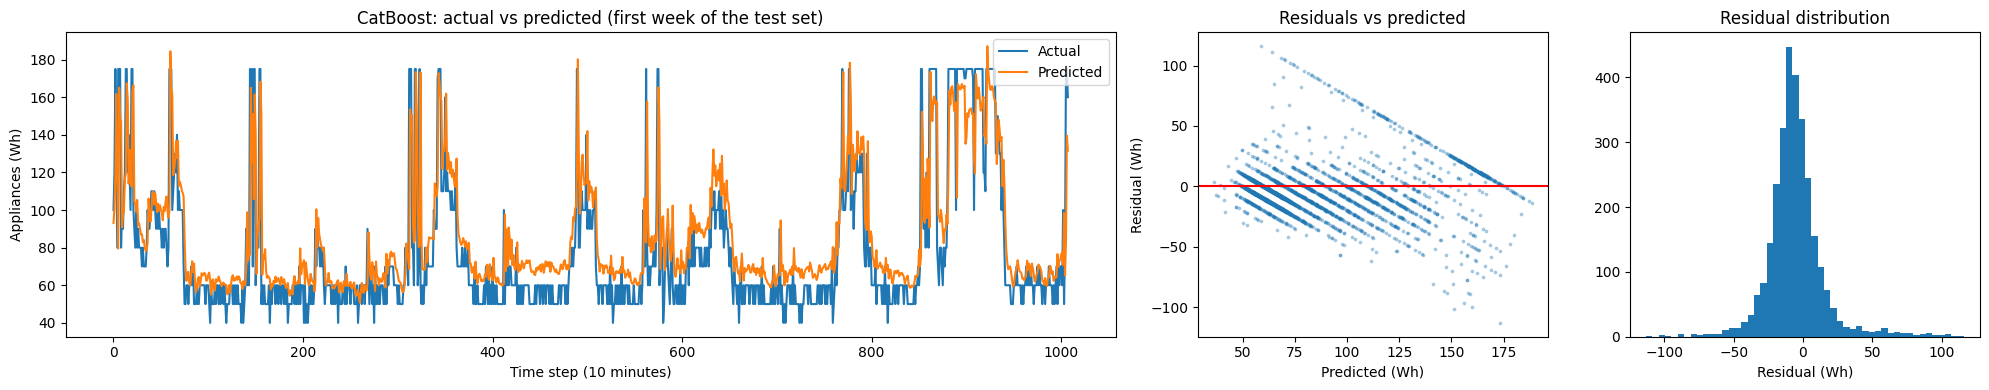

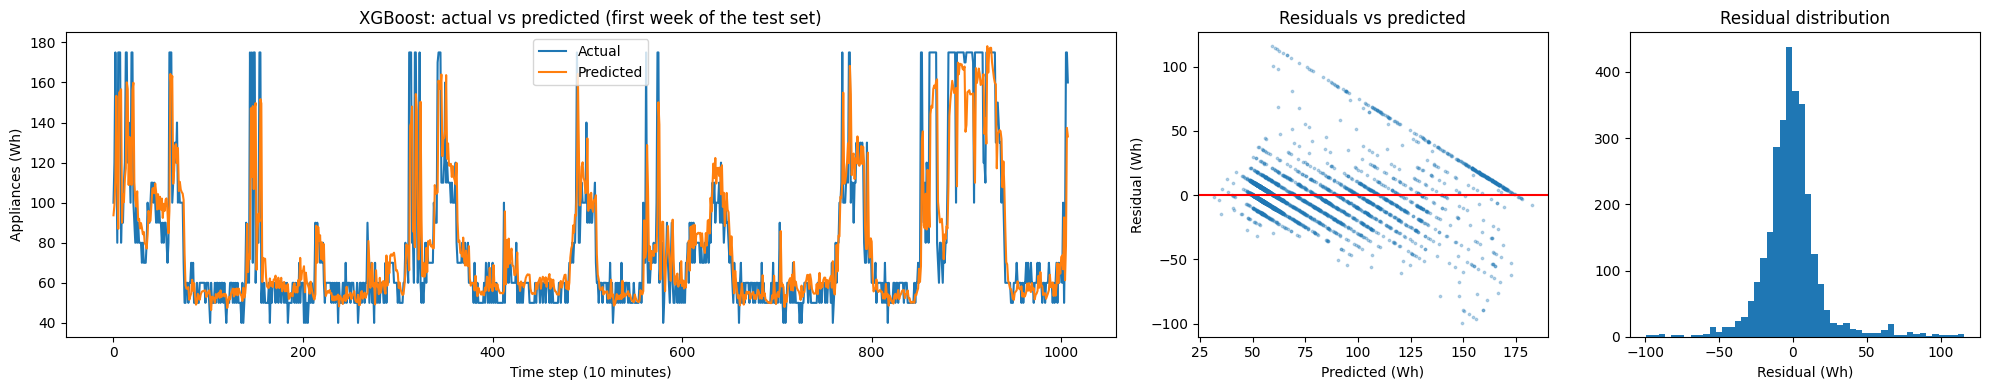

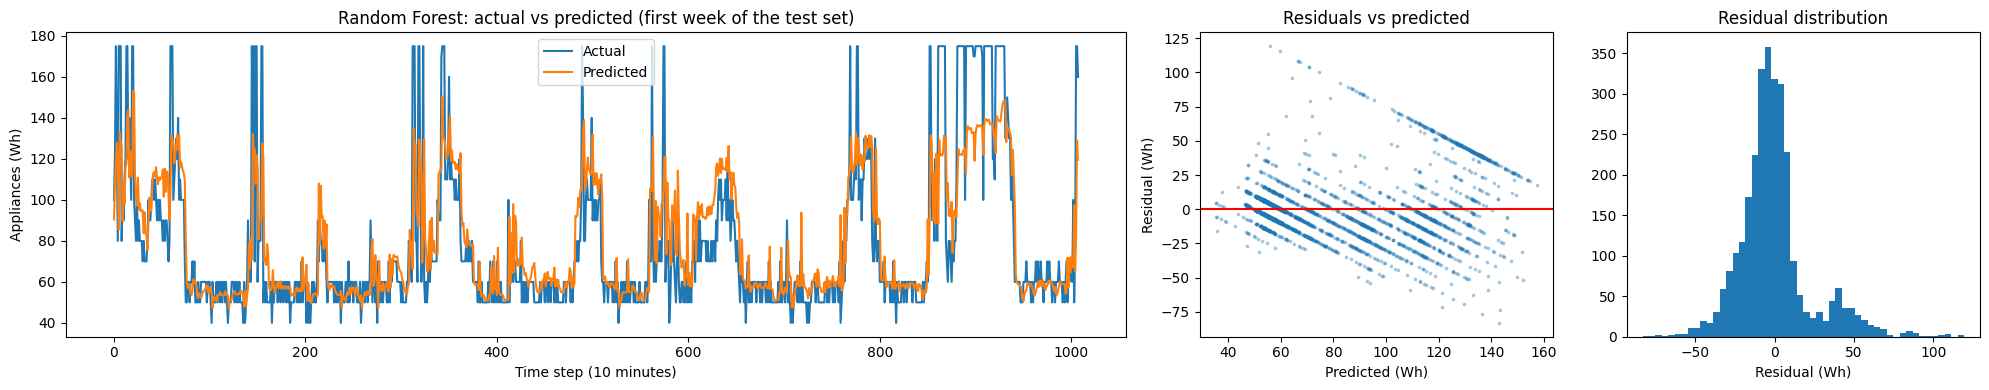

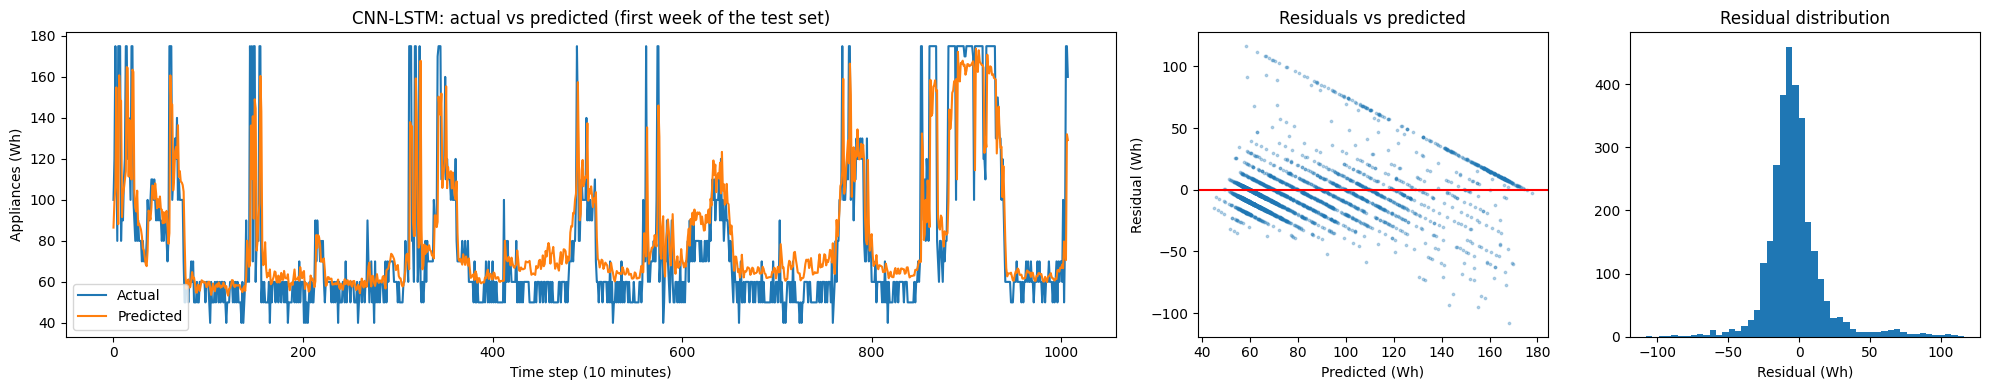

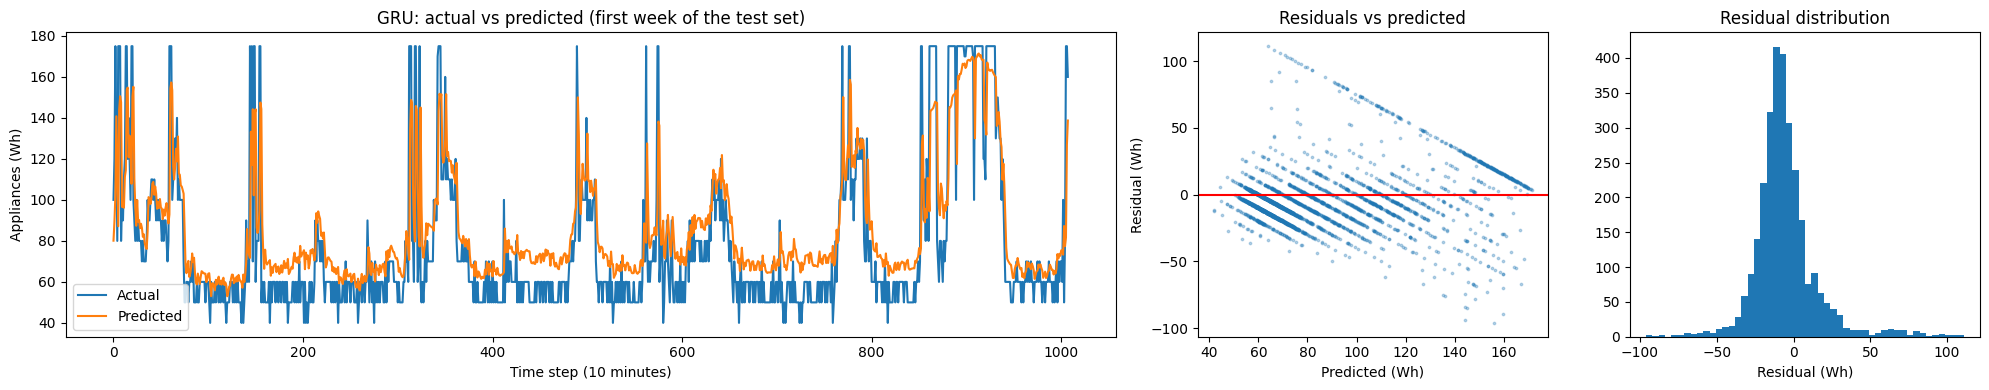

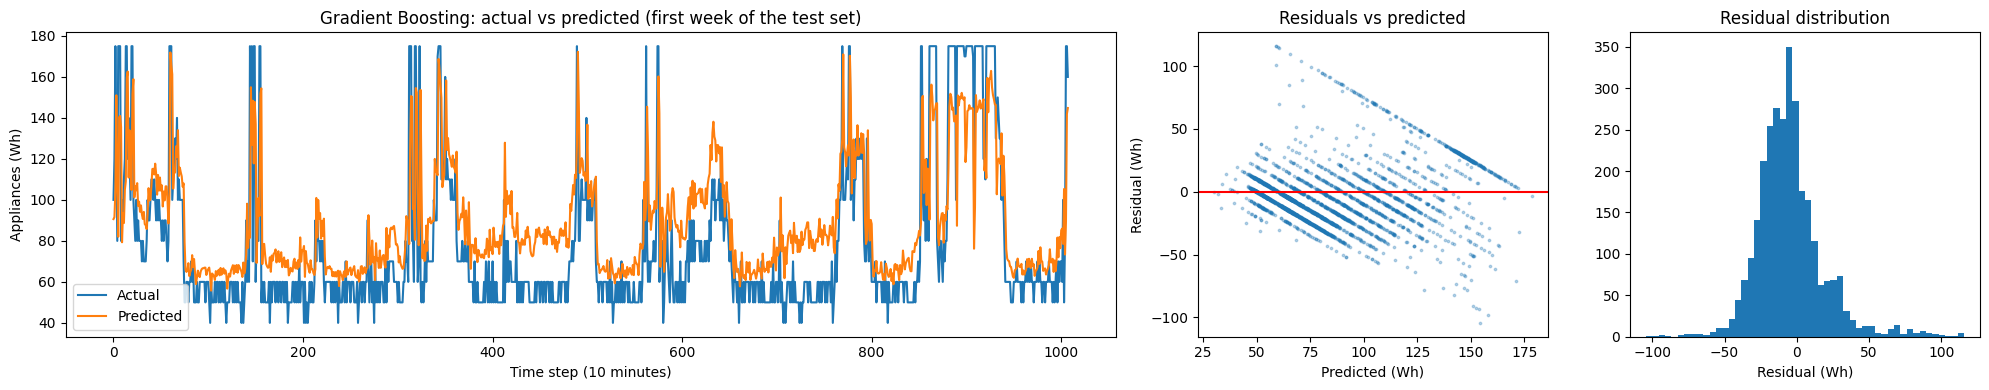

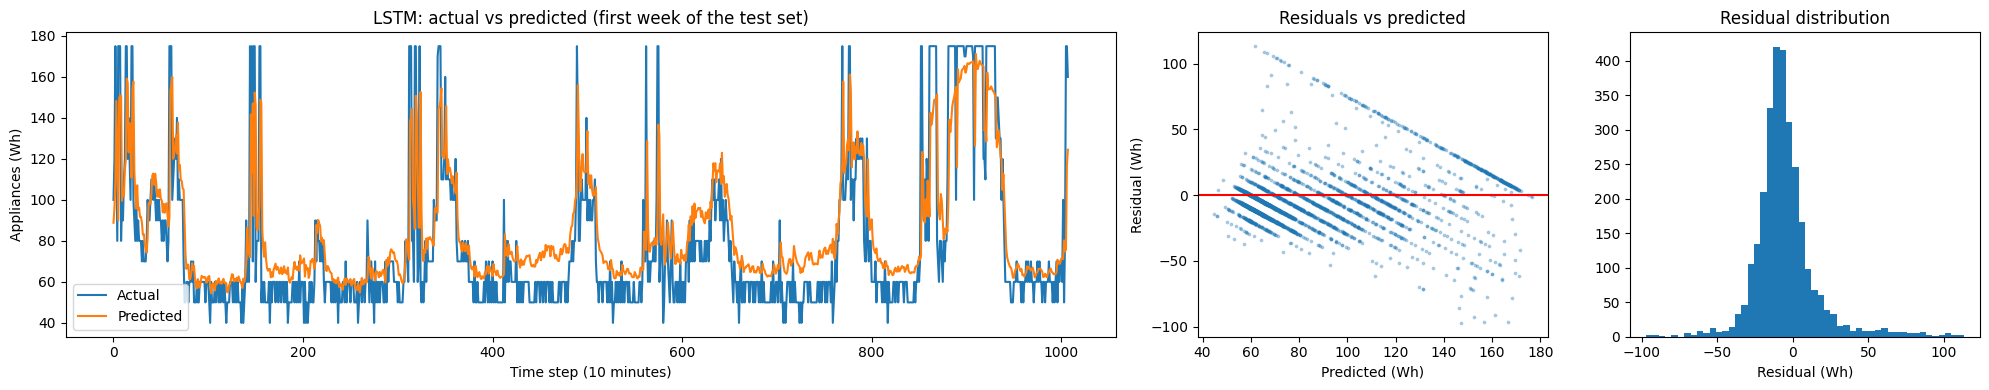

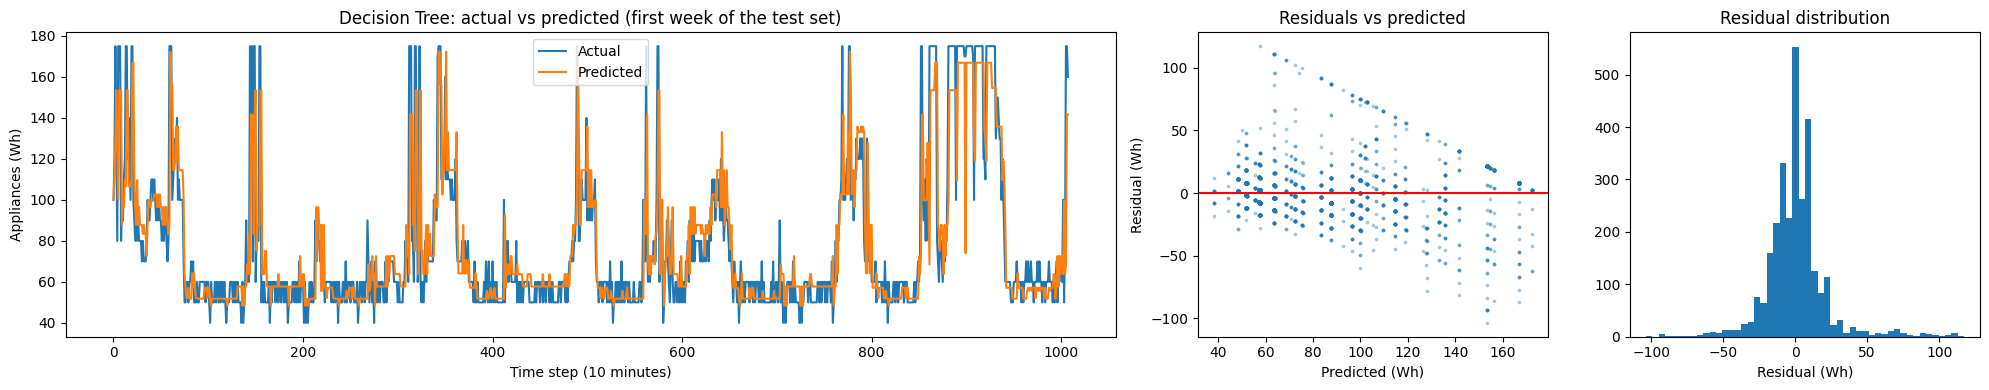

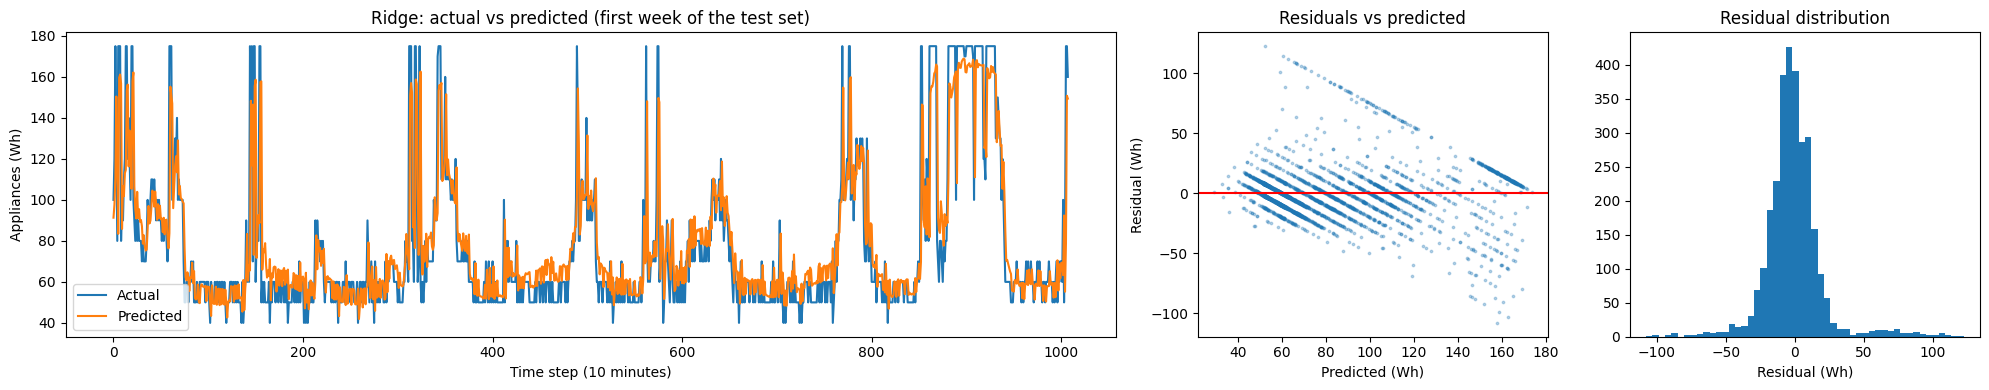

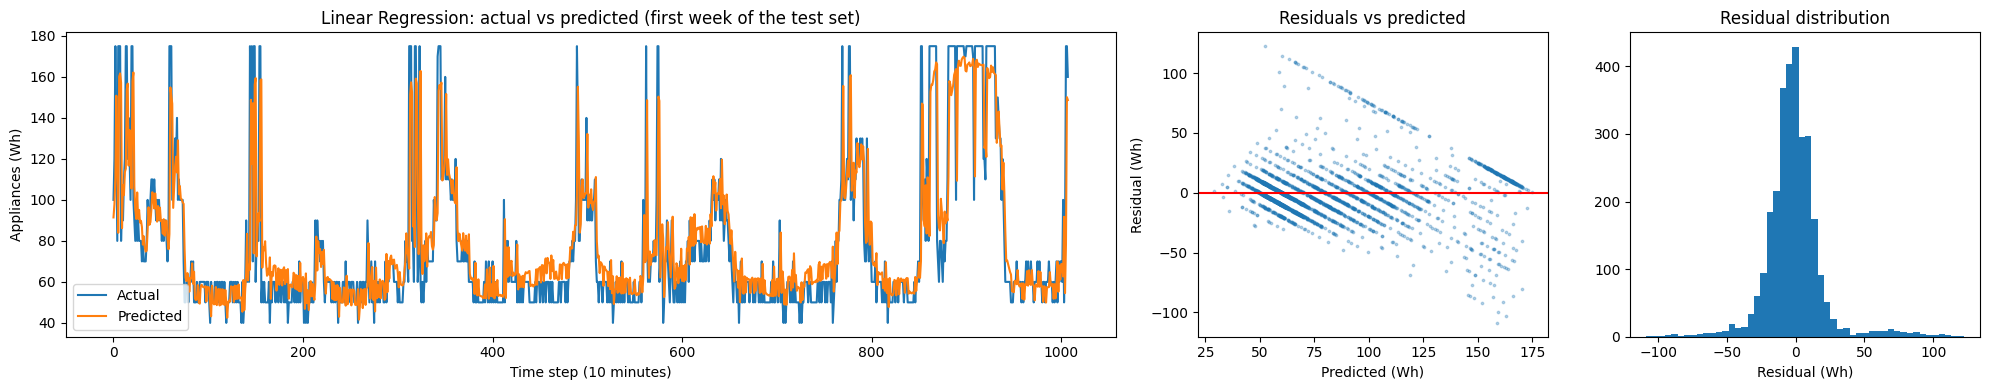

In [21]:
for _, run in best.iterrows():
    pred = predictions[run["model"]]
    week = pred.iloc[:1008]   # first week of the test set (7 days x 144 readings)
    residual = pred["actual"] - pred["predicted"]

    fig, axes = plt.subplots(1, 3, figsize=(20, 4), gridspec_kw={"width_ratios": [3, 1, 1]})
    axes[0].plot(week["actual"], label="Actual")
    axes[0].plot(week["predicted"], label="Predicted")
    axes[0].set_title(f"{run['name']}: actual vs predicted (first week of the test set)")
    axes[0].set_xlabel("Time step (10 minutes)")
    axes[0].set_ylabel("Appliances (Wh)")
    axes[0].legend()

    axes[1].scatter(pred["predicted"], residual, s=3, alpha=0.3)
    axes[1].axhline(0, color="red")
    axes[1].set_title("Residuals vs predicted")
    axes[1].set_xlabel("Predicted (Wh)")
    axes[1].set_ylabel("Residual (Wh)")

    axes[2].hist(residual, bins=50)
    axes[2].set_title("Residual distribution")
    axes[2].set_xlabel("Residual (Wh)")

    plt.tight_layout()
    plt.savefig(PER_MODEL / f"{run['model']}.png", dpi=200, bbox_inches="tight")
    plt.show()

In [22]:
grid[["name", "model_params", "learning_rate", "val_mae", "val_rmse"]].sort_values(["name", "val_rmse"]).round(2)

,name,model_params,learning_rate,val_mae,val_rmse
35,CNN-LSTM,"{""dropout"": 0.2, ""hidden_size"": 64}",0.0,13.20,20.54
34,CNN-LSTM,"{""dropout"": 0.2, ""hidden_size"": 32}",0.0,13.09,20.57
33,CNN-LSTM,"{""dropout"": 0.0, ""hidden_size"": 64}",0.0,13.23,20.57
32,CNN-LSTM,"{""dropout"": 0.0, ""hidden_size"": 32}",0.0,13.41,20.65
15,CatBoost,"{""depth"": 6, ""iterations"": 500, ""learning_rate"": 0.05}",NaN,13.05,20.29
14,CatBoost,"{""depth"": 4, ""iterations"": 500, ""learning_rate"": 0.05}",NaN,13.27,20.40
4,Decision Tree,"{""max_depth"": 6}",NaN,13.40,20.97
5,Decision Tree,"{""max_depth"": 10}",NaN,14.69,24.39
21,GRU,"{""dropout"": 0.0, ""hidden_size"": 128}",0.0,13.28,20.55
18,GRU,"{""dropout"": 0.0, ""hidden_size"": 64}",0.0,13.27,20.58


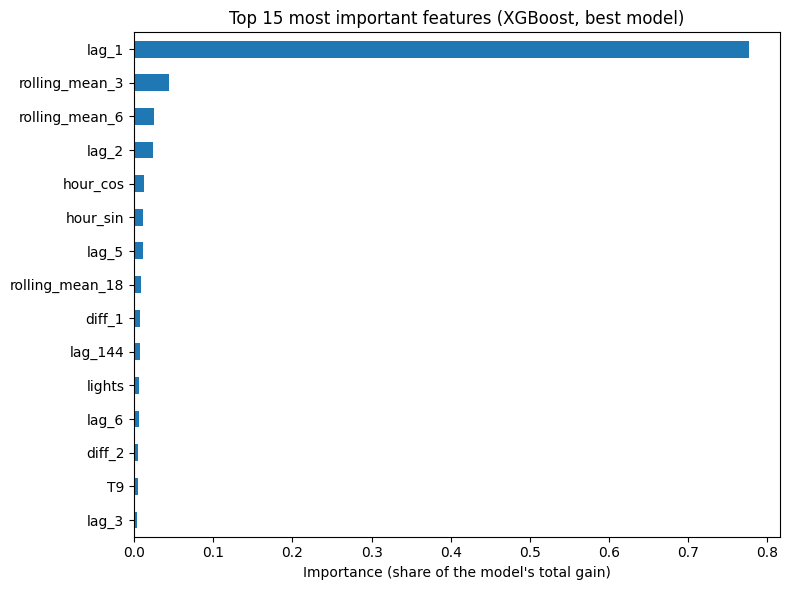

In [23]:
features = json.loads(Path("data/feature_config.json").read_text())["feature_columns"]
xgb_run = best[best["model"] == "xgboost"].iloc[0]
xgb = joblib.load(RUNS / xgb_run["run_dir"] / "model.joblib")

importance = pd.Series(xgb.feature_importances_, index=features).sort_values().tail(15)
importance.plot.barh(figsize=(8, 6))
plt.title("Top 15 most important features (XGBoost, best model)")
plt.xlabel("Importance (share of the model's total gain)")
plt.tight_layout()
plt.savefig(FIGURES / "feature_importance_xgboost.png", dpi=200, bbox_inches="tight")
plt.show()